# Stain normalisation — calibrate and look

**The question:** can each stain normalisation method map our tiles to one
colour target without damaging them, does it actually bring the two hospitals'
colours together, and what does it cost per slide?

This is the looking step before the ablation. Four methods, Reinhard in two
versions, all in `src/stain.py`, each fitted once per slide on the tissue pixels
of all its tiles and then applied to every tile:

| Method | What it matches |
|---|---|
| Reinhard | mean and spread of each LAB colour channel, every pixel mapped (glass too) |
| Reinhard, tissue only | the same, but only tissue pixels are mapped; glass is left as it is |
| Macenko | stain vectors (angular extremes in optical-density space) and stain amount |
| Vahadane | stain vectors (sparse non-negative dictionary learning) and stain amount |
| Retinex | per-stain illumination correction, then stain amount (Hamza's method, ported) |

**The targets come from Radboud slides only.** The cross-site test trains on
Radboud and tests on Karolinska; a target computed partly from Karolinska
images would let the test hospital shape the inputs. A target fixed from the
training site and applied to a new one is also how a Lahore slide would be
handled.

Why measure at all: the handbook (Stage 13) says stain normalisation "does not
always help, and it costs time at inference". For UNI2-h specifically, a kidney
study found a negligible effect, and PathoROB (2026) found Reinhard gave the
largest robustness gain of the methods it tested, about 1 point on average.
The ablation after this notebook settles it on our data.

## Preamble

In [1]:
"""Make the project's src/ folder importable.

Locally it sits one folder up from notebooks/. On Kaggle it arrives as an
attached dataset, so every attached dataset is checked for a src/ folder, and
the notebook stops with a clear message if there is none.
"""

import glob
import os
import sys

SRC_ROOT = next(
    (
        root
        for root in [os.path.abspath("..")] + sorted(glob.glob("/kaggle/input/*"))
        if os.path.isfile(os.path.join(root, "src", "tiling.py"))
    ),
    None,
)
if SRC_ROOT is None:
    raise FileNotFoundError("src/ not found; on Kaggle, attach the project's src folder as a dataset")
if SRC_ROOT not in sys.path:
    sys.path.insert(0, SRC_ROOT)

In [2]:
"""Imports.

time                  timing per method.
matplotlib            the before/after pictures.
numpy, pandas, cv2    colour statistics and the slide lists.
src.stain             the four methods, their calibration, and the tissue-pixel rule.
src.tiling            get_tiles, so the tiles are exactly the pipeline's.
src.paths             folds.csv (slide IDs and hospital, for choosing reference slides only) and slide paths.
"""

import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import stain
from src.paths import DATA_DIR, find_input, slide_path
from src.tiling import get_tiles

In [3]:
"""Settings and slides.

1. REFERENCE: 30 Radboud slides, drawn with seed 0, that the targets are
   calibrated on.
2. LOOK: 3 slides per hospital, not among the references, for the pictures.
3. MEASURE: 20 slides per hospital, not among the references, for the colour
   statistics and the timing.
The hospital is read from folds.csv only to choose these slides; the methods
themselves never see it.
"""

REFERENCE_SLIDES = 30
LOOK_PER_HOSPITAL = 3
MEASURE_PER_HOSPITAL = 20
SEED = 0

folds = pd.read_csv(find_input("folds.csv", local_dir=DATA_DIR)).set_index("slide_id")
radboud = folds.index[folds["provider"] == "radboud"]
karolinska = folds.index[folds["provider"] == "karolinska"]
rng = np.random.default_rng(SEED)
reference_ids = sorted(rng.choice(radboud, REFERENCE_SLIDES, replace=False))
rest = {name: sorted(set(ids) - set(reference_ids)) for name, ids in
        [("radboud", radboud), ("karolinska", karolinska)]}
picked = {name: list(rng.choice(ids, LOOK_PER_HOSPITAL + MEASURE_PER_HOSPITAL, replace=False))
          for name, ids in rest.items()}
look_ids = {name: ids[:LOOK_PER_HOSPITAL] for name, ids in picked.items()}
measure_ids = {name: ids[LOOK_PER_HOSPITAL:] for name, ids in picked.items()}

tiles = {s: get_tiles(slide_path(s))[0] for s in reference_ids + picked["radboud"] + picked["karolinska"]}
empty = [s for s, t in tiles.items() if not t]
print(f"{len(tiles)} slides tiled; {sum(map(len, tiles.values())):,} tiles; empty: {empty}")

folds.csv: /home/aztrek/projects/Prostate-Cancer-Grading/data/folds.csv
76 slides tiled; 4,610 tiles; empty: []


## Calibrate the targets

Each method's target is the median of its per-slide statistics over the 30
Radboud reference slides. These values go into `TARGETS` in `src/stain.py`
once the pictures below look right.

In [4]:
"""Calibrate one target per method on the reference slides, and time it."""

targets = {}
for method in stain.METHODS:
    started = time.perf_counter()
    targets[method], fitted = stain.calibrate(method, [tiles[s] for s in reference_ids])
    print(f"{method:16s} fitted on {fitted}/{len(reference_ids)} slides in {time.perf_counter() - started:5.1f} s: "
          f"{ {k: np.round(v, 4).tolist() for k, v in targets[method].items()} }")

reinhard         fitted on 30/30 slides in   2.5 s: {'mean': [175.9338, 154.062, 123.7651], 'std': [28.9135, 8.5007, 4.6925]}
reinhard_tissue  fitted on 30/30 slides in   2.5 s: {'mean': [175.9338, 154.062, 123.7651], 'std': [28.9135, 8.5007, 4.6925]}
macenko          fitted on 30/30 slides in   2.8 s: {'vectors': [[0.5286, 0.1998], [0.724, 0.8615], [0.4432, 0.4669]], 'max_c': [1.7614, 1.1988]}


/home/aztrek/projects/Prostate-Cancer-Grading/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.083109e-09, tolerance: 3.911e-09
  model = cd_fast.enet_coordinate_descent_gram(
/home/aztrek/projects/Prostate-Cancer-Grading/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.824961e-08, tolerance: 1.381e-08
  model = cd_fast.enet_coordinate_descent_gram(
/home/aztrek/projects/Prostate-Cancer-Grading/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase

vahadane         fitted on 30/30 slides in  84.3 s: {'vectors': [[0.4659, 0.2673], [0.7496, 0.8124], [0.4701, 0.5182]], 'max_c': [2.1416, 1.4531]}
retinex          fitted on 30/30 slides in  19.5 s: {'extremes': [0.4293, 0.2131]}


## Look

For each slide, the same tiles before (top row) and after each method. What
to look for: tissue that keeps its structure; haematoxylin (nuclei) still
blue-purple and eosin (stroma, cytoplasm) still pink; glass still white; no
colour blotches or banding; and Radboud and Karolinska tiles looking more alike
after than before.

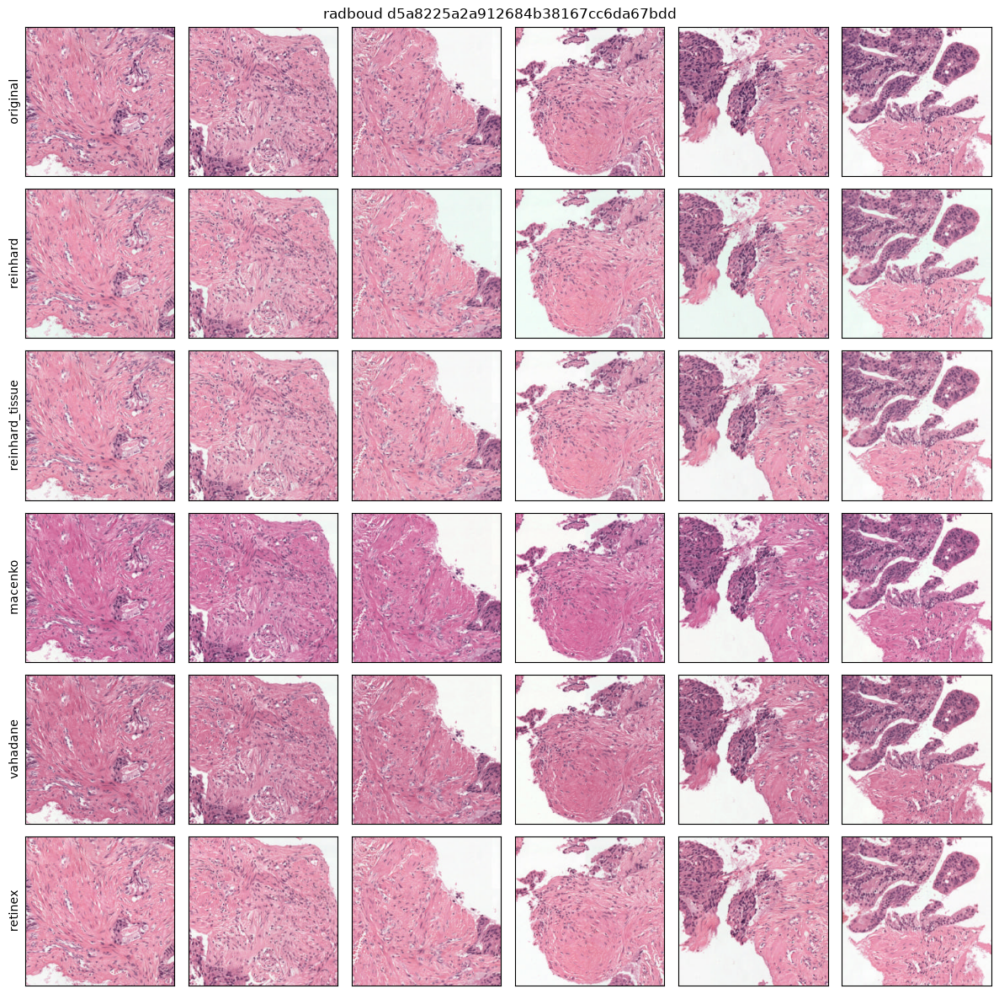

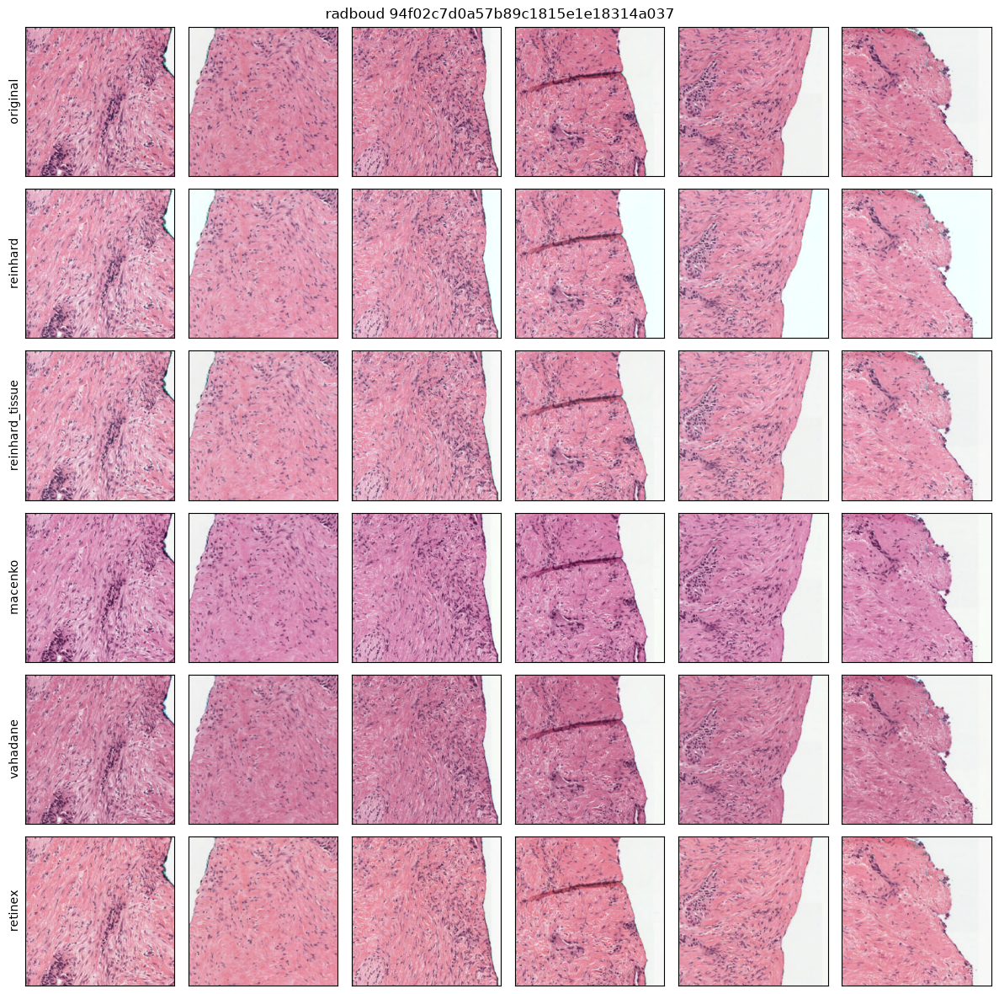

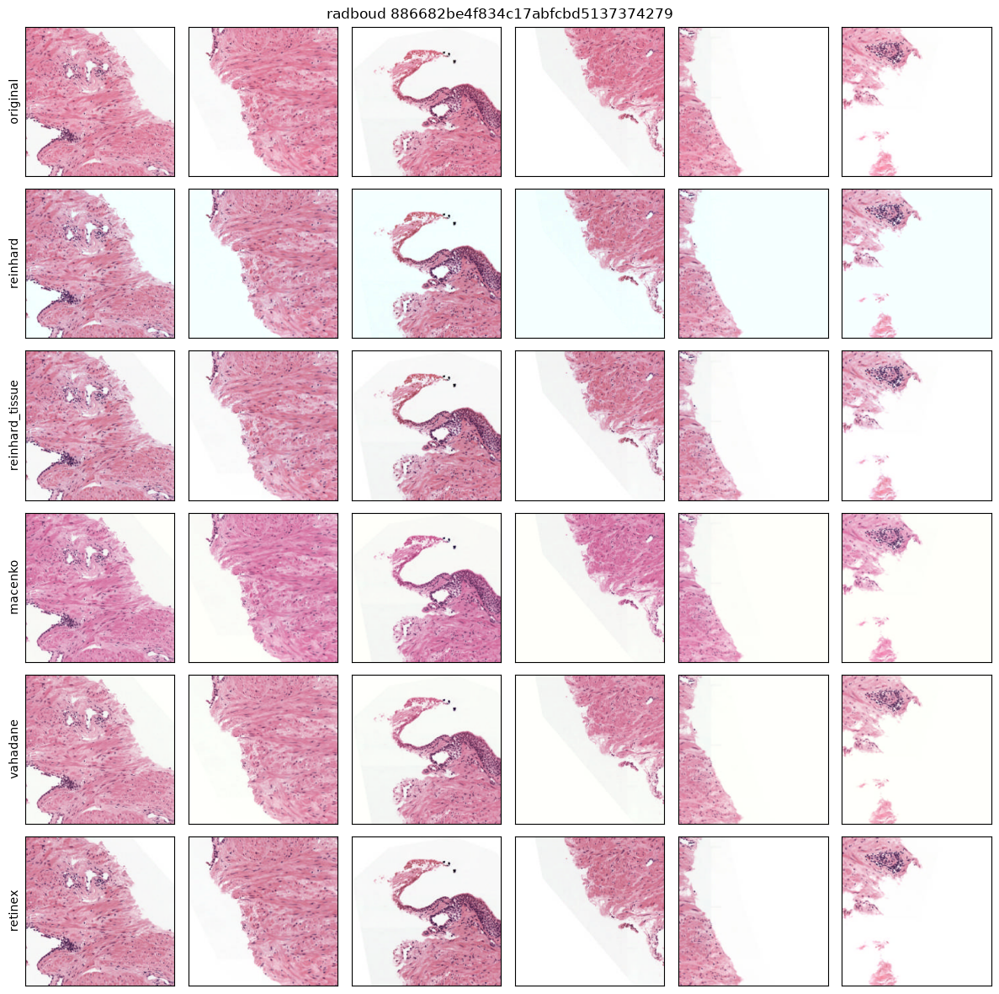

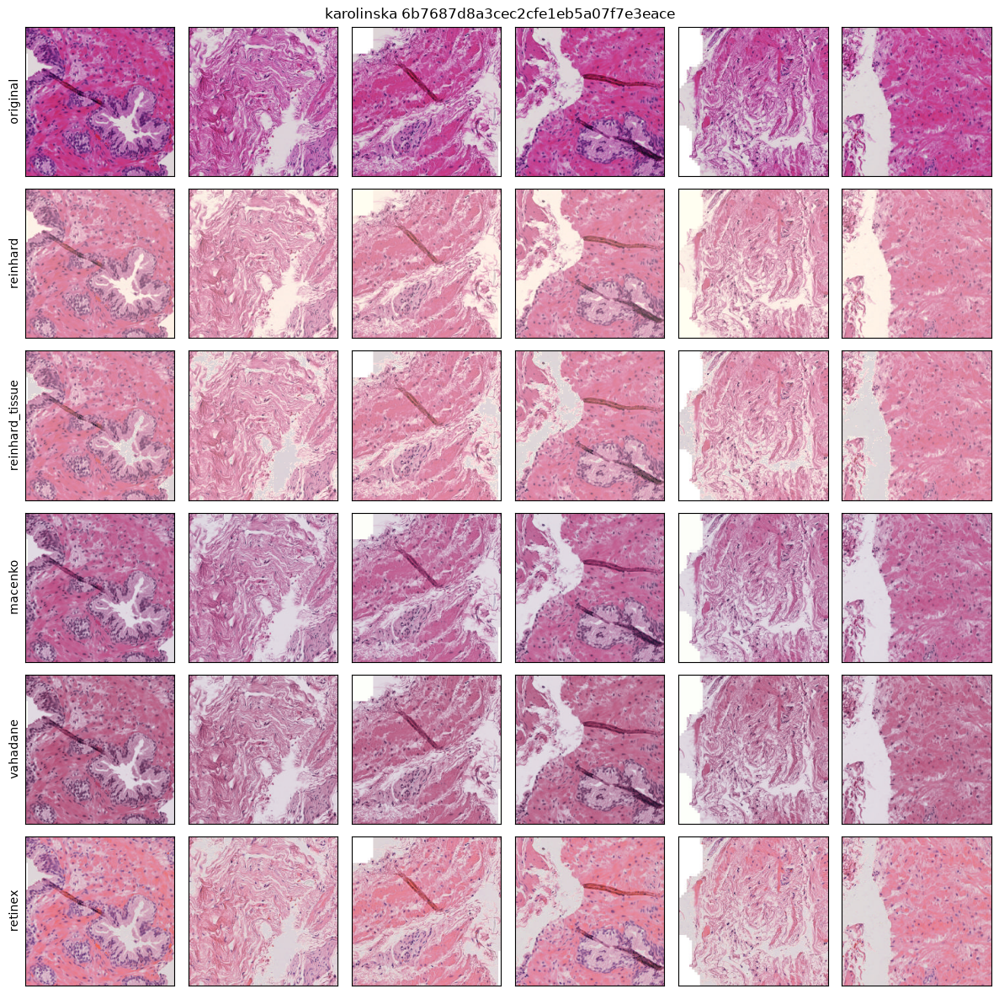

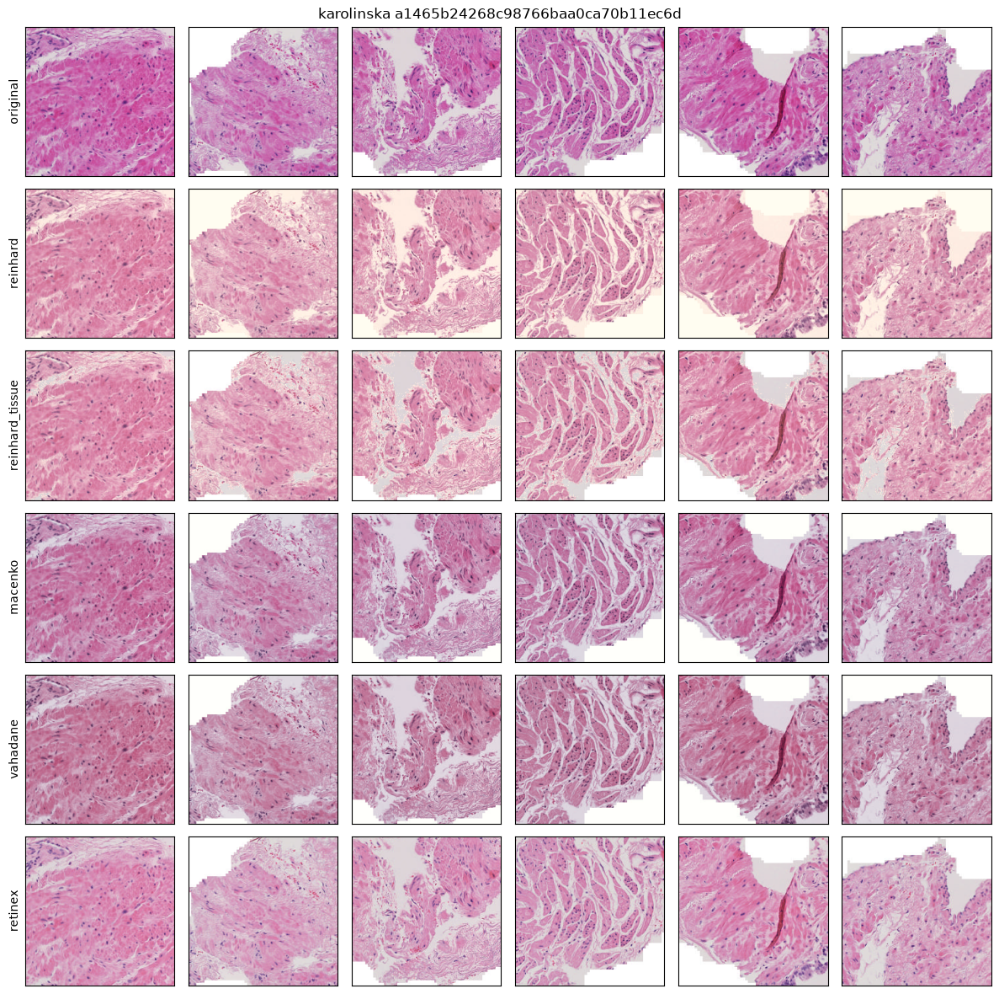

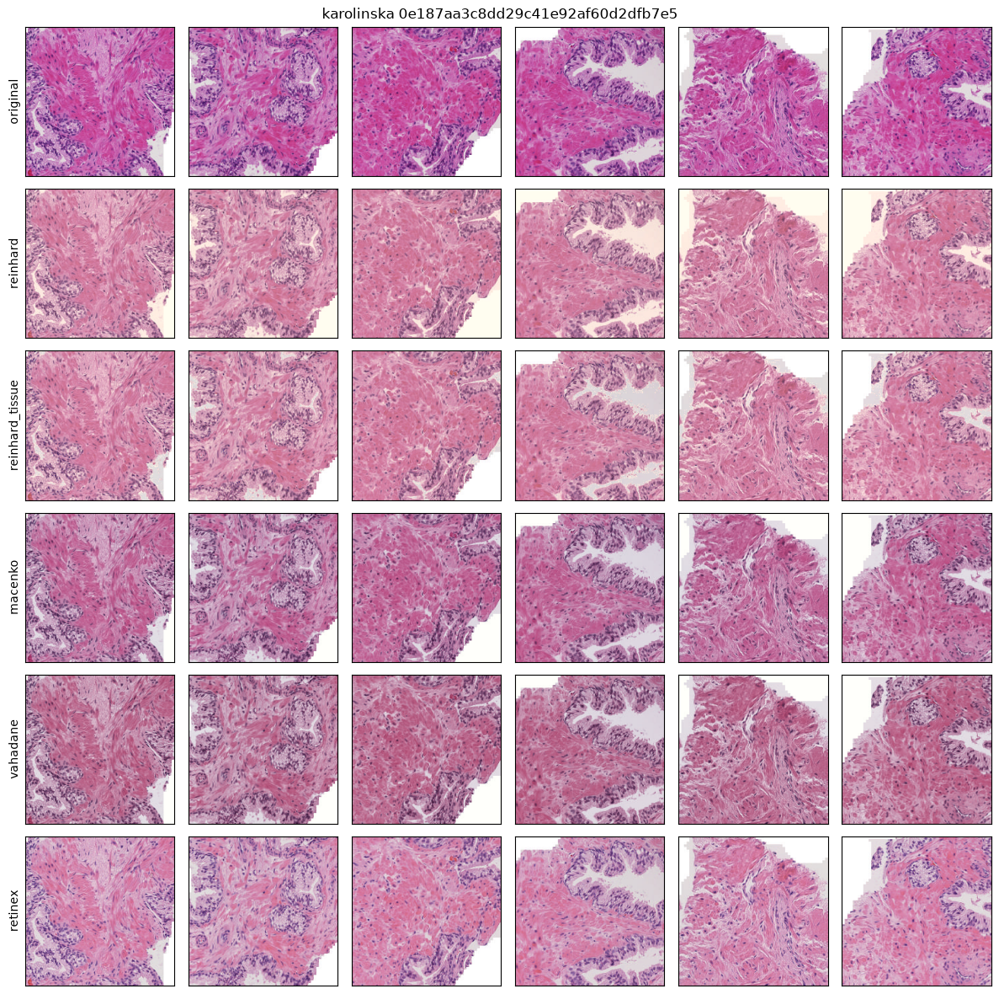

In [5]:
"""Before/after pictures: per slide, 6 tiles (the ones with most tissue among the first 30), original then each method."""

TILES_SHOWN = 6

for hospital, ids in look_ids.items():
    for slide_id in ids:
        original = tiles[slide_id]
        rows = {"original": original}
        for method in stain.METHODS:
            rows[method], fitted = stain.normalise_slide(method, original, targets[method])
            if not fitted:
                print(f"{slide_id} {method}: not fitted, tiles unchanged")
        order = np.argsort([-stain.tissue_mask(stain.to_arrays([t])).mean() for t in original[:30]])[:TILES_SHOWN]
        fig, axes = plt.subplots(len(rows), TILES_SHOWN, figsize=(2 * TILES_SHOWN, 2 * len(rows)))
        for r, (name, row_tiles) in enumerate(rows.items()):
            for c, k in enumerate(order):
                axes[r, c].imshow(row_tiles[k])
                axes[r, c].set_xticks([])
                axes[r, c].set_yticks([])
            axes[r, 0].set_ylabel(name)
        fig.suptitle(f"{hospital} {slide_id}")
        fig.tight_layout()
        plt.show()

## Does it bring the hospitals together?

The mean LAB colour of each slide's tissue pixels, before and after, for 20
slides per hospital not used in calibration. If a method works, the gap
between the two hospitals' average colours shrinks, and so does the spread
between slides within each hospital. CIE LAB is used because its distances
roughly follow perceived colour differences (OpenCV's 8-bit LAB, rescaled to
L 0-100 and a, b centred on 0).

The same loop times each method per slide, on one CPU thread.

In [6]:
"""Per slide and method: mean tissue LAB colour, and seconds to normalise.

1. For each measured slide, normalise with every method (single thread),
   timing it.
2. Mean LAB of the tissue pixels (the src.stain tissue rule) before and after.
3. Per method: distance between the hospitals' average colours, and the
   average within-hospital spread (distance of each slide from its hospital's
   average).
"""

cv2.setNumThreads(1)


def mean_lab(slide_tiles):
    arrays = stain.to_arrays(slide_tiles)
    lab = cv2.cvtColor(arrays.reshape(-1, arrays.shape[2], 3), cv2.COLOR_RGB2LAB).reshape(arrays.shape)
    lab = lab[stain.tissue_mask(arrays)].astype(np.float64)
    lab = lab.mean(axis=0)
    return np.array([lab[0] * 100 / 255, lab[1] - 128, lab[2] - 128])


rows, seconds = [], {m: [] for m in stain.METHODS}
for hospital, ids in measure_ids.items():
    for slide_id in ids:
        original = tiles[slide_id]
        if not original:
            continue
        rows.append({"hospital": hospital, "slide_id": slide_id, "method": "original", "lab": mean_lab(original)})
        for method in stain.METHODS:
            started = time.perf_counter()
            normalised, fitted = stain.normalise_slide(method, original, targets[method])
            seconds[method].append(time.perf_counter() - started)
            rows.append({"hospital": hospital, "slide_id": slide_id, "method": method, "lab": mean_lab(normalised)})
colours = pd.DataFrame(rows)

summary = []
for method, group in colours.groupby("method", sort=False):
    centres = {h: np.stack(g["lab"]).mean(axis=0) for h, g in group.groupby("hospital")}
    spread = np.mean([np.linalg.norm(np.stack(g["lab"]) - centres[h], axis=1).mean()
                      for h, g in group.groupby("hospital")])
    summary.append({"method": method,
                    "Radboud L,a,b": np.round(centres["radboud"], 1), "Karolinska L,a,b": np.round(centres["karolinska"], 1),
                    "gap between hospitals": np.linalg.norm(centres["radboud"] - centres["karolinska"]),
                    "spread within hospital": spread,
                    "s per slide (1 thread)": np.median(seconds[method]) if method in seconds else 0.0})
print(pd.DataFrame(summary).round(2).to_string(index=False))

/home/aztrek/projects/Prostate-Cancer-Grading/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.052984e-08, tolerance: 1.991e-08
  model = cd_fast.enet_coordinate_descent_gram(
/home/aztrek/projects/Prostate-Cancer-Grading/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.665108e-09, tolerance: 8.477e-09
  model = cd_fast.enet_coordinate_descent_gram(
/home/aztrek/projects/Prostate-Cancer-Grading/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:825: ConvergenceWarning: Objective did not converge. You might want to increase

         method      Radboud L,a,b    Karolinska L,a,b  gap between hospitals  spread within hospital  s per slide (1 thread)
       original [69.0, 25.6, -4.1] [57.4, 37.0, -16.8]                  20.63                    7.94                    0.00
       reinhard [71.0, 24.0, -4.0]  [76.6, 18.6, -1.0]                   8.32                    6.34                    0.23
reinhard_tissue [68.7, 26.3, -4.3]  [68.7, 26.3, -4.3]                   0.10                    0.40                    0.26
        macenko [68.8, 26.4, -8.5] [60.5, 28.6, -11.2]                   8.99                    5.39                    0.45
       vahadane [68.8, 25.0, -4.7]  [60.0, 26.5, -7.9]                   9.48                    4.97                    2.68
        retinex [69.7, 26.2, -3.6]  [68.0, 26.3, -6.9]                   3.72                    5.10                    0.97


## The targets in `src/stain.py`

The calibrated targets are written into `TARGETS` in `src/stain.py`, so
extraction and a submission need nothing but `src/`. This cell checks that
what is in the module is exactly what was calibrated above.

In [7]:
"""Compare src/stain.py's TARGETS with the targets calibrated above (to 4 decimals, as written there)."""

for method in stain.METHODS:
    written = stain.TARGETS[method]
    if written is None:
        print(f"{method:16s} not written into src/stain.py yet")
        continue
    same = all(np.allclose(np.asarray(written[key]), np.round(np.asarray(value), 4)) for key, value in targets[method].items())
    print(f"{method:16s} {'matches the calibration' if same else 'DIFFERS from the calibration'}")

reinhard         matches the calibration
reinhard_tissue  matches the calibration
macenko          matches the calibration
vahadane         matches the calibration
retinex          matches the calibration


## Result

Run 2026-11-17 on the RTX 4060 PC.

**Targets**, the median over 30 Radboud reference slides (all 30 fitted),
written into `TARGETS` in `src/stain.py` and checked above to match:

| Method | Target |
|---|---|
| Reinhard (both versions) | LAB mean (175.93, 154.06, 123.77), std (28.91, 8.50, 4.69), OpenCV 8-bit LAB |
| Macenko | H (0.529, 0.724, 0.443), E (0.200, 0.862, 0.467), max concentration (1.761, 1.199) |
| Vahadane | H (0.466, 0.750, 0.470), E (0.267, 0.812, 0.518), max concentration (2.142, 1.453) |
| Retinex | 95th-percentile density H 0.429, E 0.213 |

Calibration took 3 s (Reinhard, Macenko), 19 s (Retinex) and 83 s (Vahadane).

**Colour of tissue pixels, 20 slides per hospital** (CIE LAB; gap = distance
between the hospitals' average colours):

| Method | Gap between hospitals | Spread within a hospital | Seconds per slide, 1 thread |
|---|---|---|---|
| none | 20.6 | 7.9 | |
| Reinhard | 8.3 | 6.3 | 0.23 |
| Reinhard, tissue only | 0.1 | 0.4 | 0.26 |
| Macenko | 9.0 | 5.4 | 0.46 |
| Vahadane | 9.5 | 5.0 | 2.64 |
| Retinex | 3.7 | 5.1 | 0.96 |

Tissue-only Reinhard's near-zero gap is circular: it sets exactly the measured
quantity (the mean LAB of tissue pixels, same tissue rule) to the target. It
says the method does what it is defined to do, not that it helps the model.

**By eye:**
- Retinex: closest to a common look; Karolinska magenta becomes Radboud-like
  pink, nuclei crisp, glass untouched.
- Macenko and Vahadane: tissue intact; Karolinska stays a little more mauve
  than Radboud; Radboud glass turns faintly cream.
- Reinhard, standard: maps glass too, which turns cyan on Radboud and cream on
  Karolinska, a new hospital colour difference; Karolinska tissue washed out.
- Reinhard, tissue only: glass keeps its own colour, Karolinska tissue becomes
  Radboud-pink without washing out; faint speckle at a few pale tissue edges,
  where pixels just under the saturation cut are left unmapped.

**Decision (2026-11-17):** the ablation (notebook 14) tests tissue-only
Reinhard, Macenko, Vahadane and Retinex. Standard Reinhard is not run, because
of the glass tint.